In [1]:
import os
import shutil
import re
import collections
import pathlib
import pandas
!pip install pynrrd
#import nrrd
!pip install SimpleITK
import SimpleITK
import numpy as np
import matplotlib.pyplot as plt
import cv2
import PIL
import math
import sklearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 26.8 MB/s  0:00:02


In [2]:
import random
import tensorflow as tf
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path
datasets = Path('/content/drive/MyDrive/datasets')
datasets.mkdir(parents=True, exist_ok=True)

In [5]:

#!wget https://zenodo.org/records/13274445/files/HCFMRP_Complete_Anon_VCF_Database.rar?download=1


In [6]:
#!apt-get update
#!apt-get install unrar

In [7]:
path_mask = datasets / 'HCFMRP_Complete_Anon_VCF_Database/3-Segmentation_NRRD'

In [8]:
#!unrar x -o+ /content/HCFMRP_Complete_Anon_VCF_Database.rar?download=1 /content/drive/MyDrive/datasets/


In [9]:
dataset_path = datasets / 'HCFMRP_Complete_Anon_VCF_Database'

path_images = dataset_path / '2-Rescaled_256_NRRD'
path_mask = dataset_path / '3-Segmentation_NRRD'

print("Dataset:", dataset_path)
print("Imagens:", path_images)
print("Segmentações:", path_mask)

print("\nImagens existe?", path_images.exists())
print("Segmentações existe?", path_mask.exists())

Dataset: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database
Imagens: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/2-Rescaled_256_NRRD
Segmentações: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/3-Segmentation_NRRD

Imagens existe? True
Segmentações existe? True


In [10]:
import nrrd

In [11]:
os.chdir(path_mask)

masks = {}
masks_header = {}

sub1 = '3-Segmentation_NRRD/'
sub2 = '.seg.nrrd'

for file in os.listdir():

    if file.endswith('.nrrd'):

        file_path = str(path_mask / file)

        idx1 = file_path.index(sub1)
        idx2 = file_path.index(sub2)

        res = ''

        for idx in range(idx1 + len(sub1), idx2):
            res = res + file_path[idx]

        masks[res], masks_header[res] = nrrd.read(file_path)

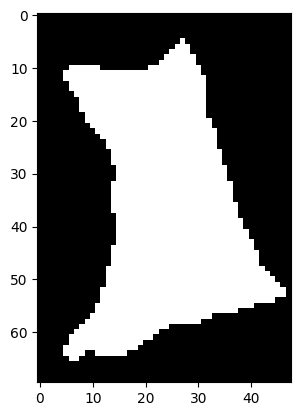

In [12]:
plt.imshow(masks['P1L1'][:, :, 0], cmap='gray')
plt.show()

In [13]:
print("Número de máscaras:", len(masks))
print(list(masks.keys())[:10])
print(masks['P1L1'].shape)

Número de máscaras: 130
['P24L5', 'P29L1', 'P42L2', 'P49L1', 'P6L5', 'P5L1', 'P35L2', 'P32L4', 'P10L1', 'P26L1']
(70, 48, 5)


In [14]:
os.chdir(path_images)

images = {}

sub1 = '2-Rescaled_256_NRRD/'
sub2 = '.nrrd'

for file in os.listdir():

    if file.endswith('.nrrd'):

        file_path = str(path_images / file)

        idx1 = file_path.index(sub1)
        idx2 = file_path.index(sub2)

        res = ''

        for idx in range(idx1 + len(sub1), idx2):
            res = res + file_path[idx]

        images[res], _ = nrrd.read(file_path)

In [15]:
print("Número de imagens:", len(images))
print(list(images.keys())[:10])
print(images['P1'].shape)

Número de imagens: 91
['P9', 'P84', 'P90', 'P85', 'P88', 'P86', 'P89', 'P91', 'P87', 'P11']
(640, 640, 14)


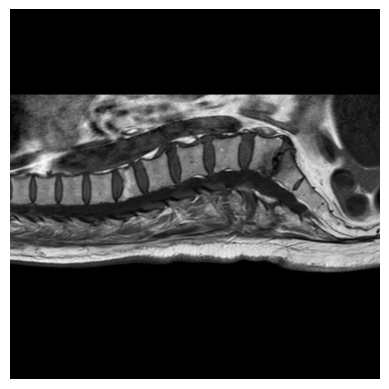

In [16]:
plt.imshow(images['P1'][:, :, 5], cmap='gray')
plt.axis('off')
plt.show()

In [17]:
print(masks_header['P1L1'])
print(masks['P1L1'][:, :].shape)
print(images['P1'][:, :].shape)

print(
    masks_header['P1L1']['Segmentation_ReferenceImageExtentOffset']
)

OrderedDict({'type': 'unsigned char', 'dimension': 3, 'space': 'right-anterior-superior', 'sizes': array([70, 48,  5]), 'space directions': array([[ 0.        , -0.52325583,  0.        ],
       [-0.02111105,  0.        , -0.52282978],
       [ 3.99674291, -0.        , -0.1613822 ]]), 'kinds': ['domain', 'domain', 'domain'], 'encoding': 'gzip', 'space origin': array([  8.12124536,   3.24763441, 181.8327767 ]), 'measurement frame': array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]]), 'Segment0_Color': '0.501961 0.682353 0.501961', 'Segment0_ColorAutoGenerated': '1', 'Segment0_Extent': '0 69 0 47 0 4', 'Segment0_ID': 'Segment_1', 'Segment0_Name': 'Segment_1', 'Segment0_NameAutoGenerated': '1', 'Segment0_Tags': 'TerminologyEntry:Segmentation category and type - 3D Slicer General Anatomy list~SRT^T-D0050^Tissue~SRT^T-D0050^Tissue~^^~Anatomic codes - DICOM master list~^^~^^|', 'Segmentation_ContainedRepresentationNames': 'Binary labelmap|', 'Segmentation_ConversionParameters': '

In [18]:
patients = pandas.read_excel(
    datasets / 'HCFMRP_Complete_Anon_VCF_Database' / 'Patients.xlsx'
)

In [19]:
path_benign = dataset_path / 'BENIGN'
path_malignant = dataset_path / 'MALIGNANT'

path_benign.mkdir(parents=True, exist_ok=True)
path_malignant.mkdir(parents=True, exist_ok=True)

In [20]:
print(patients)

     Id  Age at the exam Gender      Class Segmented Vertebra
0    P1               67      F     benign                 L1
1    P2               61      F     benign           L1/L3/L5
2    P3               65      M     benign                 L1
3    P4               84      M     benign                 L3
4    P5               78      F     benign              L1/L4
..  ...              ...    ...        ...                ...
86  P87               72      F  malignant                 L5
87  P88               68      M  malignant                 L4
88  P89               77      M  malignant                 L5
89  P90               55      M  malignant                 L4
90  P91               58      M  malignant                 L4

[91 rows x 5 columns]


In [21]:
for _, patient in patients.iterrows():

    patient_id = patient['Id']

    if patient['Class'] == 'benign':
        destination = path_benign

    elif patient['Class'] == 'malignant':
        destination = path_malignant

    else:
        continue

    image_file = path_images / f'{patient_id}.nrrd'
    mask_files = path_mask.glob(f'{patient_id}*.seg.nrrd')

    if image_file.exists():
        shutil.copy2(image_file, destination / image_file.name)

    for mask_file in mask_files:
        shutil.copy2(mask_file, destination / mask_file.name)

In [22]:
print("Arquivos BENIGN:", len(list(path_benign.iterdir())))
print("Arquivos MALIGNANT:", len(list(path_malignant.iterdir())))

Arquivos BENIGN: 168
Arquivos MALIGNANT: 107


In [23]:
import os
import re
from pathlib import Path
import numpy as np
from PIL import Image

ROOT_EXAMS = str(dataset_path)
ROOT_MASKS = str(dataset_path)

OUTPUT_ROOT = str(dataset_path / 'SAIDA')

CLASSES = ["BENIGN", "MALIGNANT"]

EXT_EXAM = ".nrrd"
EXT_MASK_PREF = ".seg.nrrd"

PATCH_HW = (150, 150)

BBOX_MARGIN = 0

SAVE_OVERLAY = True

In [24]:
try:
    import SimpleITK as sitk
except Exception:
    import sys
    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "SimpleITK"
    ])
    import SimpleITK as sitk

os.makedirs(OUTPUT_ROOT, exist_ok=True)

In [25]:
_start_digits = re.compile(r"^0*(\d+)")
_any_digits = re.compile(r"(\d+)")

def ensure_dir(p):
    os.makedirs(p, exist_ok=True)

def norm_id_from_name(fname: str, ext_hint: str) -> str:

    stem = fname[:-len(ext_hint)] if fname.lower().endswith(ext_hint.lower()) else os.path.splitext(fname)[0]

    m = _start_digits.match(stem)
    if m:
        return m.group(1)

    m2 = _any_digits.search(stem)
    return m2.group(1) if m2 else stem

In [26]:
def sitk_to_u8(arr: np.ndarray) -> np.ndarray:

    arr = arr.astype(np.float32)

    amin = float(arr.min())
    amax = float(arr.max())

    if amax > amin:
        arr = (arr - amin) / (amax - amin) * 255.0
    else:
        arr = np.zeros_like(arr)

    return arr.astype(np.uint8)

In [27]:
def resample_mask_to_exam(mask_img: sitk.Image, exam_img: sitk.Image) -> sitk.Image:

    res = sitk.ResampleImageFilter()

    res.SetReferenceImage(exam_img)
    res.SetInterpolator(sitk.sitkNearestNeighbor)
    res.SetTransform(sitk.Transform(3, sitk.sitkIdentity))
    res.SetDefaultPixelValue(0)

    return res.Execute(mask_img)

In [28]:
def best_slice_axis_index(mask_np3d: np.ndarray):

    areas = mask_np3d.reshape(mask_np3d.shape[0], -1).sum(axis=1)

    idx_z = int(np.argmax(areas))

    return 0, idx_z

In [29]:
def overlay_rgb(gray_u8: np.ndarray, mask2d: np.ndarray, alpha=0.35):

    h, w = gray_u8.shape

    rgb = np.stack([gray_u8] * 3, axis=-1).astype(np.float32)

    red = np.zeros_like(rgb)
    red[..., 0] = 255

    rgb[mask2d] = (
        (1 - alpha) * rgb[mask2d]
        + alpha * red[mask2d]
    )

    return np.clip(rgb, 0, 255).astype(np.uint8)

In [30]:
def centered_window_from_centroid(
    mask2d: np.ndarray,
    H: int,
    W: int,
    ph: int,
    pw: int,
    margin: int = 0
):

    ys, xs = np.where(mask2d)

    if ys.size == 0:
        yc, xc = H // 2, W // 2
    else:
        yc = int(round(ys.mean()))
        xc = int(round(xs.mean()))

    ph = ph + 2 * margin
    pw = pw + 2 * margin

    y0 = yc - ph // 2
    x0 = xc - pw // 2

    y1 = y0 + ph
    x1 = x0 + pw

    return y0, y1, x0, x1


def crop_with_padding(
    img: np.ndarray,
    y0: int,
    y1: int,
    x0: int,
    x1: int
):

    H, W = img.shape[:2]

    ph = y1 - y0
    pw = x1 - x0

    if img.ndim == 2:
        out = np.zeros((ph, pw), dtype=img.dtype)
    else:
        C = img.shape[2]
        out = np.zeros((ph, pw, C), dtype=img.dtype)

    src_y0 = max(0, y0)
    src_y1 = min(H, y1)

    src_x0 = max(0, x0)
    src_x1 = min(W, x1)

    dst_y0 = src_y0 - y0
    dst_x0 = src_x0 - x0

    dst_y1 = dst_y0 + (src_y1 - src_y0)
    dst_x1 = dst_x0 + (src_x1 - src_x0)

    if src_y0 < src_y1 and src_x0 < src_x1:
        out[dst_y0:dst_y1, dst_x0:dst_x1] = img[
            src_y0:src_y1,
            src_x0:src_x1
        ]

    return out

In [31]:
def normalize_class_from_path(path: str):
    parts = {p.lower() for p in Path(path).parts}

    if "benign" in parts:
        return "BENIGN"

    if "malignant" in parts:
        return "MALIGNANT"

    return None

In [32]:
exams_by_class = {cls: [] for cls in CLASSES}

for cls in CLASSES:

    p = os.path.join(ROOT_EXAMS, cls)

    if os.path.isdir(p):

        exams_by_class[cls] = sorted([
            os.path.join(p, f)
            for f in os.listdir(p)
            if f.lower().endswith(EXT_EXAM)
            and not f.lower().endswith(EXT_MASK_PREF)
        ])

In [33]:
all_masks = []

for root, _, files in os.walk(ROOT_MASKS):

    for f in files:

        if f.lower().endswith(".nrrd"):
            all_masks.append(
                os.path.join(root, f)
            )

In [34]:
masks_index = {}

for mp in all_masks:

    name = Path(mp).name

    if name.lower().endswith(EXT_MASK_PREF):
        mid = norm_id_from_name(name, EXT_MASK_PREF)
        prio = 0

    else:
        mid = norm_id_from_name(name, ".nrrd")
        prio = 1

    masks_index.setdefault(mid, []).append(
        (prio, mp)
    )

In [35]:
for k in list(masks_index.keys()):

    masks_index[k] = [
        p
        for _, p in sorted(
            masks_index[k],
            key=lambda x: x[0]
        )
    ]

print("Exames BENIGN:", len(exams_by_class["BENIGN"]))
print("Exames MALIGNANT:", len(exams_by_class["MALIGNANT"]))
print("IDs com máscaras:", len(masks_index))

Exames BENIGN: 47
Exames MALIGNANT: 44
IDs com máscaras: 91


In [36]:
# Rodar o código só uma vez #

import shutil
import os

for cls in CLASSES:
    out_dir = os.path.join(OUTPUT_ROOT, cls)

    if os.path.exists(out_dir):
        shutil.rmtree(out_dir)

print("Resultados antigos apagados.")

Resultados antigos apagados.


In [37]:
totals = {
    "processed": 0,
    "saved": 0,
    "no_mask": 0,
    "empty_mask": 0
}

PH, PW = PATCH_HW

for cls in CLASSES:

    out_dir = os.path.join(
        OUTPUT_ROOT,
        cls
    )

    out_overlay = os.path.join(
        out_dir,
        "_overlay"
    )

    ensure_dir(out_dir)

    if SAVE_OVERLAY:
        ensure_dir(out_overlay)


    processed = 0
    saved = 0
    no_mask = 0
    empty_mask = 0

    for exam_path in exams_by_class.get(cls, []):

        exam_name = Path(exam_path).name

        exam_id = norm_id_from_name(
            exam_name,
            EXT_EXAM
        )

        cand = masks_index.get(
            exam_id,
            []
        )

        picks = [
            m for m in cand
            if m.lower().endswith(".seg.nrrd")
        ]


        if not picks:

            no_mask += 1
            continue

        try:

            exam_img = sitk.ReadImage(
                exam_path
            )

            exam_np = sitk.GetArrayFromImage(
                exam_img
            )

        except Exception as e:

            print(
                f"[{cls}] ERRO lendo exame "
                f"{exam_path}: {e}"
            )

            continue

        for mask_path in picks:

            try:

                mask_img = sitk.ReadImage(
                    mask_path
                )

            except Exception as e:

                print(
                    f"[{cls}] ERRO lendo máscara "
                    f"{mask_path}: {e}"
                )

                continue

            try:

                mask_res = resample_mask_to_exam(
                    mask_img,
                    exam_img
                )

            except Exception as e:

                print(
                    f"[{cls}] ERRO no resample: {e}"
                )

                continue


            mask_np = (
                sitk.GetArrayFromImage(
                    mask_res
                ) > 0
            )

            if mask_np.sum() == 0:

                empty_mask += 1
                continue

            areas = (
                mask_np
                .reshape(
                    mask_np.shape[0],
                    -1
                )
                .sum(axis=1)
            )

            slices_com_mascara = np.where(
                areas > 0
            )[0]

            for idx in slices_com_mascara:

                mask2d = mask_np[
                    idx,
                    :,
                    :
                ]

                exam2d = exam_np[
                    idx,
                    :,
                    :
                ]

                exam2d_u8 = sitk_to_u8(
                    exam2d
                )

                masked = exam2d_u8.copy()

                masked[~mask2d] = 0

                H, W = masked.shape

                y0, y1, x0, x1 = (
                    centered_window_from_centroid(
                        mask2d,
                        H,
                        W,
                        PH,
                        PW,
                        margin=BBOX_MARGIN
                    )
                )

                patch = crop_with_padding(
                    masked,
                    y0,
                    y1,
                    x0,
                    x1
                )

                mask_stem = Path(
                    mask_path
                ).stem


                out_png = os.path.join(
                    out_dir,
                    f"{exam_id}__"
                    f"slice{idx:03d}__"
                    f"{mask_stem}__"
                    f"150x150.png"
                )

                Image.fromarray(
                    patch
                ).save(out_png)


                if SAVE_OVERLAY:

                    ov_full = overlay_rgb(
                        exam2d_u8,
                        mask2d
                    )

                    ov_patch = crop_with_padding(
                        ov_full,
                        y0,
                        y1,
                        x0,
                        x1
                    )

                    out_ov = os.path.join(
                        out_overlay,
                        f"{exam_id}__"
                        f"slice{idx:03d}__"
                        f"{mask_stem}__"
                        f"150x150_overlay.png"
                    )

                    Image.fromarray(
                        ov_patch
                    ).save(out_ov)


                saved += 1
                processed += 1


    totals["processed"] += processed
    totals["saved"] += saved
    totals["no_mask"] += no_mask
    totals["empty_mask"] += empty_mask


    print(
        f"[{cls}] Processados: {processed} | "
        f"Salvos: {saved} | "
        f"Sem máscara: {no_mask} | "
        f"Máscara vazia: {empty_mask}"
    )


print("\n===== RESUMO GERAL =====")
print(totals)
print("Saída:", OUTPUT_ROOT)

[BENIGN] Processados: 844 | Salvos: 844 | Sem máscara: 0 | Máscara vazia: 0
[MALIGNANT] Processados: 1047 | Salvos: 1047 | Sem máscara: 0 | Máscara vazia: 0

===== RESUMO GERAL =====
{'processed': 1891, 'saved': 1891, 'no_mask': 0, 'empty_mask': 0}
Saída: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SAIDA


In [38]:
for cls in CLASSES:

    patch_dir = Path(
        OUTPUT_ROOT
    ) / cls

    patches = [
        p for p in patch_dir.iterdir()
        if p.suffix.lower() == ".png"
    ]

    print(
        f"{cls}: {len(patches)} patches"
    )

BENIGN: 417 patches
MALIGNANT: 367 patches


Classe: BENIGN
Arquivo: 10__slice000__P10L3.seg__150x150.png
Tamanho: (150, 150)


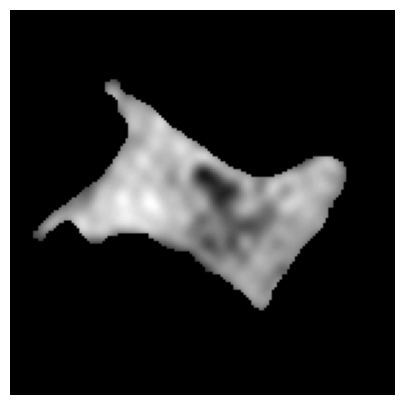

Classe: MALIGNANT
Arquivo: 11__slice002__P11L2.seg__150x150.png
Tamanho: (150, 150)


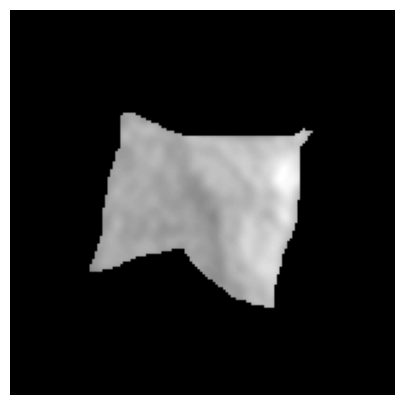

In [39]:
for cls in CLASSES:

    patch_dir = Path(
        OUTPUT_ROOT
    ) / cls

    patches = sorted([
        p for p in patch_dir.iterdir()
        if p.suffix.lower() == ".png"
    ])

    if patches:

        img = Image.open(
            patches[0]
        )

        print(
            f"Classe: {cls}"
        )
        print(
            f"Arquivo: {patches[0].name}"
        )
        print(
            f"Tamanho: {img.size}"
        )

        plt.figure(figsize=(5, 5))
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        plt.show()

In [40]:
import os
import re
import random
import shutil
from pathlib import Path
import pandas as pd

SEED = 42

SOURCE_ROOT = Path(OUTPUT_ROOT)
SPLIT_ROOT = SOURCE_ROOT.parent / "SPLIT"

CLASSES = ["BENIGN", "MALIGNANT"]

CLASS_MAP = {
    "BENIGN": "benign",
    "MALIGNANT": "malignant"
}

RATIOS = {
    "train": 0.70,
    "validation": 0.20,
    "test": 0.10
}

OVERWRITE = False

In [41]:
def get_patient_id(filename):

    stem = Path(filename).stem

    if "__" in stem:
        patient_id = stem.split("__")[0]

        if patient_id:
            return patient_id

    match = re.search(r"\d+", stem)

    if match:
        return match.group(0)

    return stem

In [42]:
for split in ["train", "validation", "test"]:

    for cls in CLASS_MAP.values():

        destination = SPLIT_ROOT / split / cls

        destination.mkdir(
            parents=True,
            exist_ok=True
        )

print("Pastas de destino criadas em:")
print(SPLIT_ROOT)

Pastas de destino criadas em:
/content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SPLIT


In [43]:
files_by_class_patient = {}

for cls in CLASSES:

    source_class_dir = SOURCE_ROOT / cls

    files_by_class_patient[cls] = {}

    if not source_class_dir.exists():
        print(f"Atenção: pasta não encontrada: {source_class_dir}")
        continue

    for file in source_class_dir.iterdir():

        if file.name == "_overlay":
            continue

        if not file.is_file():
            continue

        if file.suffix.lower() != ".png":
            continue

        patient_id = get_patient_id(file.name)

        if patient_id not in files_by_class_patient[cls]:
            files_by_class_patient[cls][patient_id] = []

        files_by_class_patient[cls][patient_id].append(file)


for cls in CLASSES:

    print(
        f"{cls}: "
        f"{len(files_by_class_patient[cls])} pacientes"
    )

BENIGN: 47 pacientes
MALIGNANT: 44 pacientes


In [44]:
for cls in CLASSES:

    print(f"\n===== {cls} =====")

    patients = files_by_class_patient[cls]

    for patient_id, files in sorted(patients.items()):

        print(
            f"{patient_id}: "
            f"{len(files)} patch(es)"
        )


===== BENIGN =====
1: 5 patch(es)
10: 44 patch(es)
14: 13 patch(es)
16: 9 patch(es)
18: 5 patch(es)
19: 7 patch(es)
2: 18 patch(es)
20: 5 patch(es)
21: 6 patch(es)
22: 7 patch(es)
24: 23 patch(es)
27: 7 patch(es)
29: 5 patch(es)
3: 6 patch(es)
30: 5 patch(es)
31: 6 patch(es)
32: 13 patch(es)
33: 5 patch(es)
34: 6 patch(es)
35: 30 patch(es)
4: 5 patch(es)
5: 10 patch(es)
53: 5 patch(es)
54: 6 patch(es)
55: 10 patch(es)
56: 12 patch(es)
57: 6 patch(es)
59: 6 patch(es)
6: 16 patch(es)
60: 8 patch(es)
62: 6 patch(es)
63: 5 patch(es)
64: 5 patch(es)
65: 5 patch(es)
66: 7 patch(es)
67: 8 patch(es)
68: 5 patch(es)
69: 7 patch(es)
70: 5 patch(es)
71: 5 patch(es)
8: 18 patch(es)
82: 4 patch(es)
83: 7 patch(es)
84: 6 patch(es)
85: 5 patch(es)
86: 4 patch(es)
9: 6 patch(es)

===== MALIGNANT =====
11: 5 patch(es)
12: 6 patch(es)
13: 7 patch(es)
15: 11 patch(es)
17: 8 patch(es)
23: 10 patch(es)
25: 5 patch(es)
26: 26 patch(es)
28: 6 patch(es)
36: 6 patch(es)
37: 6 patch(es)
38: 20 patch(es)
39: 6 

In [45]:
patients_by_class = {
    cls: set(files_by_class_patient[cls].keys())
    for cls in CLASSES
}

common_patients = (
    patients_by_class["BENIGN"]
    & patients_by_class["MALIGNANT"]
)

if common_patients:

    print(
        "ATENÇÃO! Os seguintes pacientes aparecem "
        "nas duas classes:"
    )

    print(sorted(common_patients))

else:

    print(
        "OK: nenhum paciente aparece nas duas classes."
    )

OK: nenhum paciente aparece nas duas classes.


In [46]:
rng = random.Random(SEED)

splits_by_class = {}

for cls in CLASSES:

    patients = list(
        files_by_class_patient[cls].keys()
    )

    rng.shuffle(patients)

    n = len(patients)

    n_train = int(round(n * RATIOS["train"]))
    n_validation = int(round(n * RATIOS["validation"]))

    n_test = n - n_train - n_validation

    train_patients = patients[:n_train]

    validation_patients = patients[
        n_train:n_train + n_validation
    ]

    test_patients = patients[
        n_train + n_validation:
    ]

    splits_by_class[cls] = {
        "train": train_patients,
        "validation": validation_patients,
        "test": test_patients
    }

    print(f"\n===== {cls} =====")

    print(
        "Train:",
        len(train_patients),
        "pacientes"
    )

    print(
        "Validation:",
        len(validation_patients),
        "pacientes"
    )

    print(
        "Test:",
        len(test_patients),
        "pacientes"
    )


===== BENIGN =====
Train: 33 pacientes
Validation: 9 pacientes
Test: 5 pacientes

===== MALIGNANT =====
Train: 31 pacientes
Validation: 9 pacientes
Test: 4 pacientes


In [47]:
for cls in CLASSES:

    train_set = set(
        splits_by_class[cls]["train"]
    )

    validation_set = set(
        splits_by_class[cls]["validation"]
    )

    test_set = set(
        splits_by_class[cls]["test"]
    )

    assert train_set.isdisjoint(validation_set), (
        f"Erro: paciente compartilhado entre "
        f"train e validation em {cls}"
    )

    assert train_set.isdisjoint(test_set), (
        f"Erro: paciente compartilhado entre "
        f"train e test em {cls}"
    )

    assert validation_set.isdisjoint(test_set), (
        f"Erro: paciente compartilhado entre "
        f"validation e test em {cls}"
    )


print(
    "OK: nenhum paciente foi colocado "
    "em mais de um split dentro da mesma classe."
)

OK: nenhum paciente foi colocado em mais de um split dentro da mesma classe.


In [48]:
copy_stats = {
    "train": 0,
    "validation": 0,
    "test": 0
}

for cls in CLASSES:

    destination_class = CLASS_MAP[cls]

    for split in ["train", "validation", "test"]:

        patients = splits_by_class[cls][split]

        destination_dir = (
            SPLIT_ROOT
            / split
            / destination_class
        )

        destination_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        for patient_id in patients:

            files = files_by_class_patient[
                cls
            ][patient_id]

            for source_file in files:

                destination_file = (
                    destination_dir
                    / source_file.name
                )

                if (
                    destination_file.exists()
                    and not OVERWRITE
                ):
                    continue

                shutil.copy2(
                    source_file,
                    destination_file
                )

                copy_stats[split] += 1


print("Cópia concluída.")

print(
    "Train:",
    copy_stats["train"],
    "arquivos"
)

print(
    "Validation:",
    copy_stats["validation"],
    "arquivos"
)

print(
    "Test:",
    copy_stats["test"],
    "arquivos"
)

Cópia concluída.
Train: 0 arquivos
Validation: 0 arquivos
Test: 0 arquivos


In [49]:
for split in ["train", "validation", "test"]:

    print(f"\n===== {split.upper()} =====")

    for cls in ["benign", "malignant"]:

        directory = (
            SPLIT_ROOT
            / split
            / cls
        )

        files = [
            f for f in directory.iterdir()
            if f.is_file()
            and f.suffix.lower() == ".png"
        ]

        print(
            f"{cls}: {len(files)} imagens"
        )


===== TRAIN =====
benign: 265 imagens
malignant: 238 imagens

===== VALIDATION =====
benign: 74 imagens
malignant: 85 imagens

===== TEST =====
benign: 78 imagens
malignant: 44 imagens


### Contagem de Patches Individual por Exame/Paciente

O código abaixo agrupa os arquivos gerados no diretório de saída por ID de exame e exibe a quantidade exata de fatias (patches) obtidas para cada um deles.

In [50]:
import pandas as pd

resumo_data = []
total_images = 0

for classe, pacientes in files_by_class_patient.items():
    for paciente_id, lista_arquivos in pacientes.items():
        resumo_data.append({
            'Classe': classe,
            'ID Paciente': paciente_id,
            'Quantidade de Patches': len(lista_arquivos)
        })
        total_images += len(lista_arquivos)
df_resumo = pd.DataFrame(resumo_data)

df_resumo = df_resumo.sort_values(by=['Classe', 'Quantidade de Patches'], ascending=[True, False]).reset_index(drop=True)

print("=== CONTAGEM DE PATCHES POR EXAME ===")
display(df_resumo)

print(f'total_images: {total_images}')

=== CONTAGEM DE PATCHES POR EXAME ===


,Classe,ID Paciente,Quantidade de Patches
0,BENIGN,10,44
1,BENIGN,35,30
2,BENIGN,24,23
3,BENIGN,2,18
4,BENIGN,8,18
...,...,...,...
86,MALIGNANT,73,5
87,MALIGNANT,90,5
88,MALIGNANT,58,4
89,MALIGNANT,72,4


total_images: 784


In [51]:
split_patients = {}

for split in ["train", "validation", "test"]:

    split_patients[split] = set()

    for cls in ["benign", "malignant"]:

        directory = (
            SPLIT_ROOT
            / split
            / cls
        )

        if not directory.exists():
            continue

        for file in directory.iterdir():

            if not file.is_file():
                continue

            if file.suffix.lower() != ".png":
                continue

            patient_id = get_patient_id(
                file.name
            )

            split_patients[split].add(
                patient_id
            )


train_patients = split_patients["train"]
validation_patients = split_patients["validation"]
test_patients = split_patients["test"]


assert train_patients.isdisjoint(
    validation_patients
)

assert train_patients.isdisjoint(
    test_patients
)

assert validation_patients.isdisjoint(
    test_patients
)


print(
    "OK: nenhum paciente aparece em "
    "mais de um split."
)

OK: nenhum paciente aparece em mais de um split.


In [52]:
manifest = []

for split in ["train", "validation", "test"]:

    for cls in ["benign", "malignant"]:

        directory = (
            SPLIT_ROOT
            / split
            / cls
        )

        if not directory.exists():
            continue

        for file in directory.iterdir():

            if not file.is_file():
                continue

            if file.suffix.lower() != ".png":
                continue

            patient_id = get_patient_id(
                file.name
            )

            manifest.append({
                "filepath": str(file),
                "split": split,
                "class": cls,
                "patient_id": patient_id
            })


manifest_df = pd.DataFrame(
    manifest
)

manifest_path = (
    SPLIT_ROOT / "manifest.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False
)

print(
    "Manifest salvo em:",
    manifest_path
)

print(
    "Total de imagens:",
    len(manifest_df)
)

Manifest salvo em: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SPLIT/manifest.csv
Total de imagens: 784


In [53]:
print("\n========== RESUMO FINAL ==========")

print(
    f"Train:       {len(split_patients['train'])} pacientes"
)

print(
    f"Validation:  {len(split_patients['validation'])} pacientes"
)

print(
    f"Test:        {len(split_patients['test'])} pacientes"
)

print(
    f"\nTotal de pacientes únicos: "
    f"{len(set().union(*split_patients.values()))}"
)

print(
    "\nPasta dos splits:"
)

print(SPLIT_ROOT)


========== RESUMO FINAL ==========
Train:       64 pacientes
Validation:  18 pacientes
Test:        9 pacientes

Total de pacientes únicos: 91

Pasta dos splits:
/content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SPLIT


Principais bibliotecas para o treinamento

In [54]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data.dataloader import DataLoader
from torch.utils.data import ConcatDataset
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path
import random
import matplotlib.pyplot as plt

In [55]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

Uso de transformações de inverter os eixos e normalizar

In [56]:
train_transform = transforms.Compose([
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

default_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

rotation_transform = transforms.Compose([
    transforms.RandomApply([transforms.RandomRotation(degrees=15)], p=0.8),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Transformação das imagens para iteráveis

In [57]:
BATCH_SIZE = 32

train_dataset_origin = datasets.ImageFolder(root = SPLIT_ROOT/'train', transform=default_transform)
train_dataset_transform = datasets.ImageFolder(root = SPLIT_ROOT/'train', transform=train_transform)
train_dataset_rotation = datasets.ImageFolder(root = SPLIT_ROOT/'train', transform=rotation_transform)

validation_dataset = datasets.ImageFolder(root = SPLIT_ROOT/'validation', transform=test_transform)

test_dataset = datasets.ImageFolder(root = SPLIT_ROOT/'test', transform=default_transform)

train_dataset = ConcatDataset([train_dataset_origin, train_dataset_transform, train_dataset_rotation])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f'train_dataset: {train_dataset}, size: {len(train_dataset)}')
print(f'test_dataset: {test_dataset}, size: {len(test_dataset)}')
print(f'validation_dataset: {validation_dataset}, size: {len(validation_dataset)}')

train_dataset: <torch.utils.data.dataset.ConcatDataset object at 0x7ec06cc0e900>, size: 1509
test_dataset: Dataset ImageFolder
    Number of datapoints: 122
    Root location: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SPLIT/test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           ), size: 122
validation_dataset: Dataset ImageFolder
    Number of datapoints: 159
    Root location: /content/drive/MyDrive/datasets/HCFMRP_Complete_Anon_VCF_Database/SPLIT/validation
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           ), size: 159


Uso do modelo resnet101 e do densenet121 por transfer learning

In [91]:
weight_res = torchvision.models.ResNet101_Weights
model_res = torchvision.models.resnet101(weights=weight_res).to(device)

In [92]:
for param in model_res.parameters():
  param.requires_grad = False

features = model_res.fc.in_features
model_res.fc = torch.nn.Sequential(
                  torch.nn.Dropout(p=0.5),
                  torch.nn.Linear(features, out_features=2, device=device)
                )

In [93]:
weight_den = torchvision.models.DenseNet121_Weights
model_den = torchvision.models.densenet121(weights=weight_den).to(device)

In [94]:
for param in model_den.parameters():
  param.requires_grad = False

features = model_den.classifier.in_features
model_den.classifier = torch.nn.Sequential(
                  torch.nn.Dropout(p=0.5),
                  torch.nn.Linear(features, out_features=2, device=device)
                )

Uso da função de perda entropia cruzada e do otimizador Adam

In [95]:
loss = torch.nn.CrossEntropyLoss(label_smoothing=0.1)
EPOCHS = 30

In [96]:
optimizer_res = torch.optim.Adam(
      filter(lambda p: p.requires_grad, model_res.parameters()),
      lr=0.001, weight_decay=1e-2
    )
scheduler_res = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer_res, T_0=EPOCHS, eta_min=1e-5)

In [97]:
optimizer_den = torch.optim.Adam(
      filter(lambda p: p.requires_grad, model_den.parameters()),
      lr=0.001, weight_decay=1e-2
    )
scheduler_den = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer_den, T_0=EPOCHS, eta_min=1e-5)

In [65]:
model_dir = Path('/content/drive/MyDrive/datasets/modelos')
model_dir.mkdir(parents=True, exist_ok=True)

Etapa de treino

In [66]:
def train_step(dataloader: torch.utils.data.dataloader, model: torch.nn.Module, loss_fn: torch.nn.Module, optimizer: torch.optim.Optimizer, device: torch.device):
  train_loss, train_acc = 0.0, 0.0
  model.train()
  for X, y in dataloader:
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    pred_label = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (pred_label == y).sum().item()/len(pred_label)
  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  return train_loss, train_acc

Etapa de teste

In [67]:
def val_step(dataloader: torch.utils.data.dataloader, model: torch.nn.Module, loss_fn: torch.nn.Module, device: torch.device):
  model.eval()
  accuracy, test_loss = 0.0, 0.0
  with torch.no_grad():
    for X, y in dataloader:
      X, y = X.to(device), y.to(device)
      pred = model(X)
      loss = loss_fn(pred, y)
      test_loss += loss.item()
      pred_label = torch.argmax(torch.softmax(pred, dim=1), dim=1)
      accuracy += (pred_label == y).sum().item()/len(pred_label)
    test_loss = test_loss / len(dataloader)
    accuracy = accuracy / len(dataloader)
  return test_loss, accuracy

Execução do treinamento

In [68]:
def train(model: torch.nn.Module, train_loader: torch.utils.data.dataloader,
          validation_loader: torch.utils.data.dataloader, optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module, epochs: int, device: torch.device,
          scheduler: torch.optim.lr_scheduler, caminho: str):
    accuracy_train_list = []
    accuracy_test_list = []
    loss_train_list = []
    loss_test_list = []
    best_acc = 0.0
    best_loss = 10.0
    modelo = str
    for epoch in range(epochs):
      train_loss, train_acc = train_step(train_loader, model, loss_fn, optimizer, device)
      loss_train_list.append(train_loss)
      accuracy_train_list.append(train_acc)
      test_loss, test_acc = val_step(validation_loader, model, loss_fn, device)
      accuracy_test_list.append(test_acc)
      loss_test_list.append(test_loss)
      print(f'Epoch: {epoch+1}, train_loss: {train_loss:.4f}, train_acc: {train_acc:.4f}, test_loss: {test_loss:.4f}, test_acc: {test_acc:.4f}')
      scheduler.step()
      if best_acc < test_acc and best_loss > test_loss and epoch + 1 > EPOCHS - 10:
        best_acc = test_acc
        best_loss = test_loss
        torch.save(model, f"{model_dir}/{caminho}.pth")
    modelo = f'{model_dir}/{caminho}.pth'
    return loss_train_list, loss_test_list, accuracy_train_list, accuracy_test_list, modelo

In [69]:
def plota_dados(caminho: str):
  plt.figure(figsize=(10, 4))
  df = pd.read_csv(caminho)

  ax1 = plt.subplot(1, 2, 1)
  ax1.plot(df['epoch'], df['loss_train'], label='loss_train')
  ax1.set_ylim(bottom=0.2, top=0.7)
  plt.xlabel('epoch')

  ax1.plot(df['epoch'], df['loss_test'], label='loss_val')
  ax1.grid(True)
  ax1.legend()

  ax2 = plt.subplot(1, 2, 2)
  ax2.plot(df['epoch'], df['acc_train'], label='acc_train')
  plt.xlabel('epoch')
  ax2.set_ylim(bottom=0.5, top=1.0)

  ax2.plot(df['epoch'], df['acc_test'], label='acc_val')
  ax2.grid(True)
  ax2.legend()
  plt.show()

def salva_dados(epoch: int, loss_train_list: list, loss_test_list: list, accuracy_train_list: list, accuracy_test_list: list, modelo: str) -> str:
  data = []
  for i in range(epoch):
    data.append(
        {
        'epoch': i+1,
        'loss_train': loss_train_list[i],
        'loss_test': loss_test_list[i],
        'acc_train': accuracy_train_list[i],
        'acc_test': accuracy_test_list[i]
        }
    )
  df = pd.DataFrame(data)
  caminho = f'{model_dir}/{modelo}.csv'
  df.to_csv(caminho, index=False)
  print('CSV salvo com sucesso')

  return caminho

In [70]:
def validation(images: list, model: torch.nn.Module, device: torch.device):
  y_pred = []
  y_label = []
  y_prob = []
  model.eval()
  for image_path in images:
    cls = os.path.basename(os.path.dirname(image_path))
    with torch.no_grad():
      image = Image.open(image_path).convert('RGB')
      image = test_transform(image).unsqueeze(0).to(device)
      pred = model(image)
      pred = torch.softmax(pred, dim=1)
      y_prob.append(pred)
      pred_label = torch.argmax(pred, dim=1)
      y_pred.append(pred_label)

      if cls == 'benign':
        y_label.append(0)
      else:
        y_label.append(1)
  return y_pred, y_label, y_prob

In [71]:
def intervalo_confianca(y_pred: list, y_label: list, y_prob: list, rodadas: int):
  probs = torch.cat(y_prob, dim=0)
  prob_pos = probs[:,1]
  if type(y_pred[0]) != int:
    for i in range(len(y_pred)):
      y_pred[i] = y_pred[i].item()

  y_test = np.array(y_label)
  y_pred_np = np.array(y_pred)

  rng = np.random.default_rng(42)
  scores = []

  for i in range(rodadas):
    idx = rng.choice(len(y_test), size=len(y_test), replace=True)
    scores.append(accuracy_score(y_test[idx], y_pred_np[idx]))

  inferior, superior = np.percentile(scores, [2.5, 97.5])
  print(f'accuracy: {accuracy_score(y_test, y_pred_np)}')
  print(f'intervalo de confianca: [{inferior:.2f}, {superior:.2f}]')
  return prob_pos

In [72]:
def curva_roc(prob_pos: list, y_label: list, rodadas: int):
  probabilidades = []
  for i in range(len(prob_pos)):
    probabilidades.append(prob_pos[i].item())
  auc = roc_auc_score(y_label, probabilidades)
  print(f'ROC-AUC: {auc:.2f}')

  fpr, tpr, limiares = roc_curve(y_label, probabilidades)

  plt.plot(fpr, tpr, label=f"Modelo (AUC = {auc:.3f})")
  plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatório (AUC = 0.500)")
  plt.xlabel("Taxa de Falsos Positivos (FPR)")
  plt.ylabel("Taxa de Verdadeiros Positivos (TPR / Recall)")
  plt.title("Curva ROC")
  plt.legend()
  plt.show()

  y_real = np.array(y_label)
  y_prob_np = np.array(prob_pos.cpu())

  rng = np.random.default_rng(42)
  aucs = []

  for _ in range(rodadas):
    idx = rng.choice(len(y_real), size=len(y_real), replace=True)
    if len(np.unique(y_real[idx])) < 2:
      continue
    score = roc_auc_score(y_real[idx], y_prob_np[idx])
    aucs.append(score)

  auc = roc_auc_score(y_real, y_prob_np)
  ic_inferior, ic_superior = np.percentile(aucs, [2.5, 97.5])
  print(f'AUC: {auc:.2f}')
  print(f'IC 95% da AUC: [{ic_inferior:.2f}, {ic_superior:.2f}]')

In [73]:
def matriz_confusao(y_label: list, y_pred: list):
  cm = confusion_matrix(y_label, y_pred)
  ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot()

Epoch: 1, train_loss: 0.5954, train_acc: 0.7065, test_loss: 0.6834, test_acc: 0.7312
Epoch: 2, train_loss: 0.5049, train_acc: 0.7768, test_loss: 0.4726, test_acc: 0.8306
Epoch: 3, train_loss: 0.5240, train_acc: 0.7742, test_loss: 0.4539, test_acc: 0.8246
Epoch: 4, train_loss: 0.4715, train_acc: 0.8197, test_loss: 0.5134, test_acc: 0.7802
Epoch: 5, train_loss: 0.4944, train_acc: 0.8018, test_loss: 0.4866, test_acc: 0.7869
Epoch: 6, train_loss: 0.4501, train_acc: 0.8283, test_loss: 0.4913, test_acc: 0.7742
Epoch: 7, train_loss: 0.4725, train_acc: 0.8318, test_loss: 0.4767, test_acc: 0.7933
Epoch: 8, train_loss: 0.4877, train_acc: 0.8072, test_loss: 0.4431, test_acc: 0.8308
Epoch: 9, train_loss: 0.4709, train_acc: 0.8223, test_loss: 0.4530, test_acc: 0.8058
Epoch: 10, train_loss: 0.4490, train_acc: 0.8376, test_loss: 0.4534, test_acc: 0.8373
Epoch: 11, train_loss: 0.4660, train_acc: 0.8194, test_loss: 0.4536, test_acc: 0.8246
Epoch: 12, train_loss: 0.4513, train_acc: 0.8383, test_loss: 0.

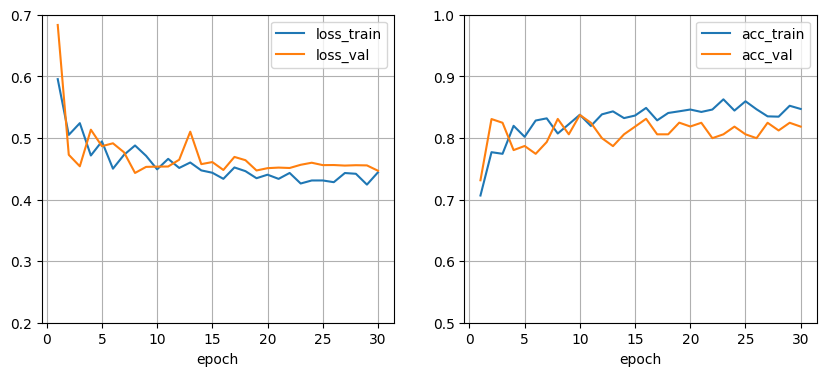

In [98]:
loss_train, loss_test, acc_train, acc_test, modelo_salvo = train(model_res,
                                                  train_loader, validation_loader,
                                                   optimizer_res, loss, EPOCHS, device, scheduler_res, 'model_resnet')
caminho = salva_dados(EPOCHS, loss_train, loss_test, acc_train, acc_test, 'resnet')
plota_dados(caminho)

In [99]:
model = torch.load(f='/content/drive/MyDrive/datasets/modelos/model_resnet.pth', weights_only=False)
test_image = list((SPLIT_ROOT/'test').glob('*/*'))
random.shuffle(test_image)
preds, labels, probs = validation(test_image, model, device)
print(f'total images: {len(test_image)}')
probs_pos = intervalo_confianca(preds, labels, probs, 10000)

total images: 122
accuracy: 0.8688524590163934
intervalo de confianca: [0.80, 0.93]


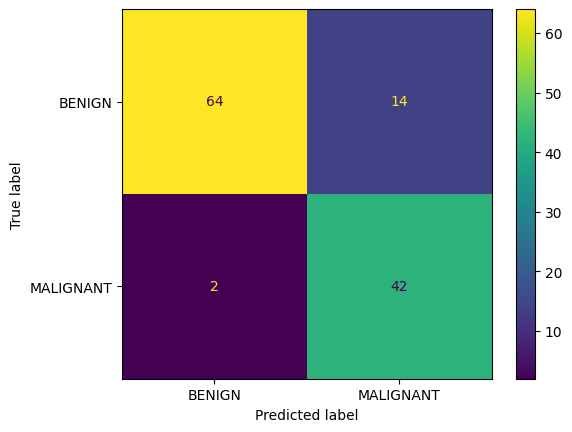

In [100]:
matriz_confusao(labels, preds)

ROC-AUC: 0.95


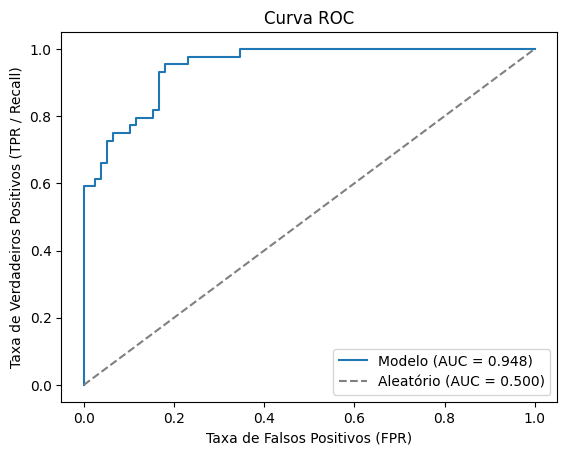

/tmp/ipykernel_350/3200570124.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_prob_np = np.array(prob_pos.cpu())


AUC: 0.95
IC 95% da AUC: [0.91, 0.98]


In [101]:
curva_roc(probs_pos, labels, 10000)

Epoch: 1, train_loss: 0.6615, train_acc: 0.6615, test_loss: 0.6335, test_acc: 0.6788
Epoch: 2, train_loss: 0.5575, train_acc: 0.7526, test_loss: 0.4910, test_acc: 0.8556
Epoch: 3, train_loss: 0.5388, train_acc: 0.7594, test_loss: 0.4758, test_acc: 0.8369
Epoch: 4, train_loss: 0.5296, train_acc: 0.7703, test_loss: 0.4759, test_acc: 0.8308
Epoch: 5, train_loss: 0.5243, train_acc: 0.7773, test_loss: 0.4434, test_acc: 0.8371
Epoch: 6, train_loss: 0.4925, train_acc: 0.8099, test_loss: 0.4421, test_acc: 0.8433
Epoch: 7, train_loss: 0.4958, train_acc: 0.8005, test_loss: 0.4323, test_acc: 0.8371
Epoch: 8, train_loss: 0.4977, train_acc: 0.7908, test_loss: 0.4313, test_acc: 0.8371
Epoch: 9, train_loss: 0.5047, train_acc: 0.7966, test_loss: 0.4420, test_acc: 0.8433
Epoch: 10, train_loss: 0.5026, train_acc: 0.7898, test_loss: 0.4590, test_acc: 0.8496
Epoch: 11, train_loss: 0.5156, train_acc: 0.7779, test_loss: 0.4599, test_acc: 0.8308
Epoch: 12, train_loss: 0.5294, train_acc: 0.7749, test_loss: 0.

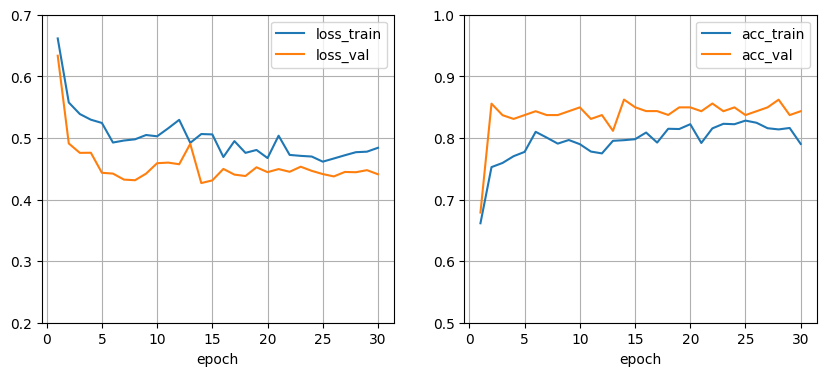

In [102]:
loss_train, loss_test, acc_train, acc_test, modelo_salvo = train(model_den,
                                                  train_loader, validation_loader,
                                                   optimizer_den, loss, EPOCHS, device, scheduler_den, 'model_densenet')
caminho = salva_dados(EPOCHS, loss_train, loss_test, acc_train, acc_test, 'densenet')
plota_dados(caminho)

In [103]:
model = torch.load(f=modelo_salvo, weights_only=False)
test_image = list((SPLIT_ROOT/'test').glob('*/*'))
random.shuffle(test_image)
preds, labels, probs = validation(test_image, model, device)
print(f'total images: {len(test_image)}')
probs_pos = intervalo_confianca(preds, labels, probs, 10000)

total images: 122
accuracy: 0.8688524590163934
intervalo de confianca: [0.80, 0.93]


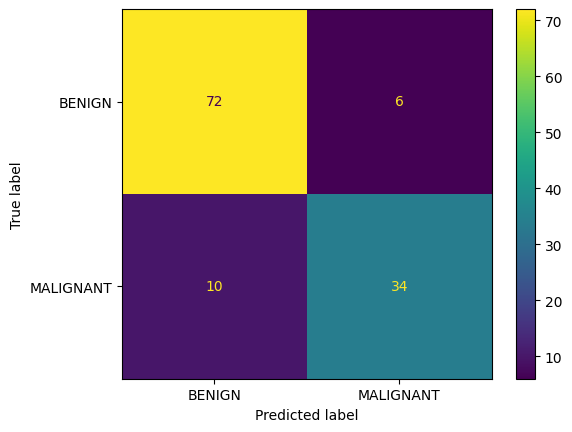

In [104]:
matriz_confusao(labels, preds)

ROC-AUC: 0.93


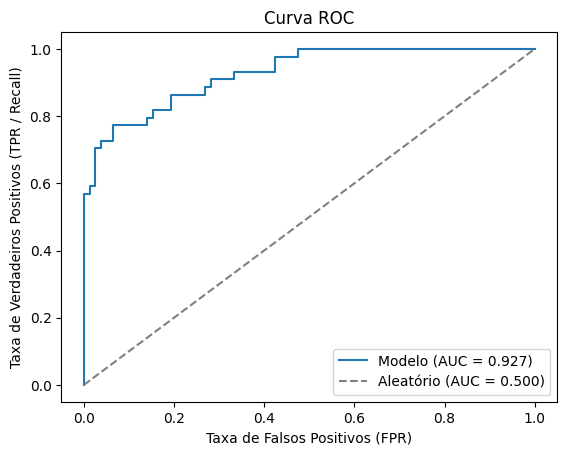

/tmp/ipykernel_350/3200570124.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  y_prob_np = np.array(prob_pos.cpu())


AUC: 0.93
IC 95% da AUC: [0.88, 0.97]


In [105]:
curva_roc(probs_pos, labels, 10000)